# SHAP Interpretation: From Model to Biomarker Shortlist
## Part 3 of 3: Explainable AI for Assay Prioritisation

**Goal.** Turn the cross-validated model from Notebook 2 into a short, defensible list of metabolites worth quantifying in a targeted validation assay.

**Approach.** Several lines of evidence per metabolite:
1. **SHAP importance** from the best model (ridge logistic, `shap.LinearExplainer`): mean |SHAP| in log-odds units
2. **Univariate significance** before *and after* PQN dilution correction (Welch t-test + Benjamini–Hochberg FDR, Notebook 1)
3. **Selection stability:** how often the nested-CV Lasso kept the metabolite (Notebook 2)

Notebook 1 showed that cachexic urine is globally more concentrated, so a key question here is which metabolites the model uses *beyond* that global shift.

> SHAP is computed on a model fitted to all 77 patients. It explains *what the model uses*, not out-of-sample performance (that is Notebook 2's job).


In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

DATA = Path("../../data/human_cachexia.csv")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
PALETTE = {"Cachexic": "#E74C3C", "Control": "#3498DB"}

import shap
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

df = pd.read_csv(DATA)
X = df.drop(columns=["Sample", "Condition"])
y = (df["Condition"] == "Cachexic").astype(int)   # 1 = Cachexic

scaler = StandardScaler().fit(np.log2(X))
X_std = pd.DataFrame(scaler.transform(np.log2(X)), columns=X.columns)
model = LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000).fit(X_std, y)
assert model.classes_[1] == 1, "positive SHAP must mean 'towards Cachexic'"

explainer = shap.LinearExplainer(model, X_std)
shap_vals = explainer(X_std)
print(f"SHAP matrix: {shap_vals.values.shape} (patients x metabolites); positive = pushes towards Cachexic")


SHAP matrix: (77, 63) (patients x metabolites); positive = pushes towards Cachexic


## 1. Global importance and direction

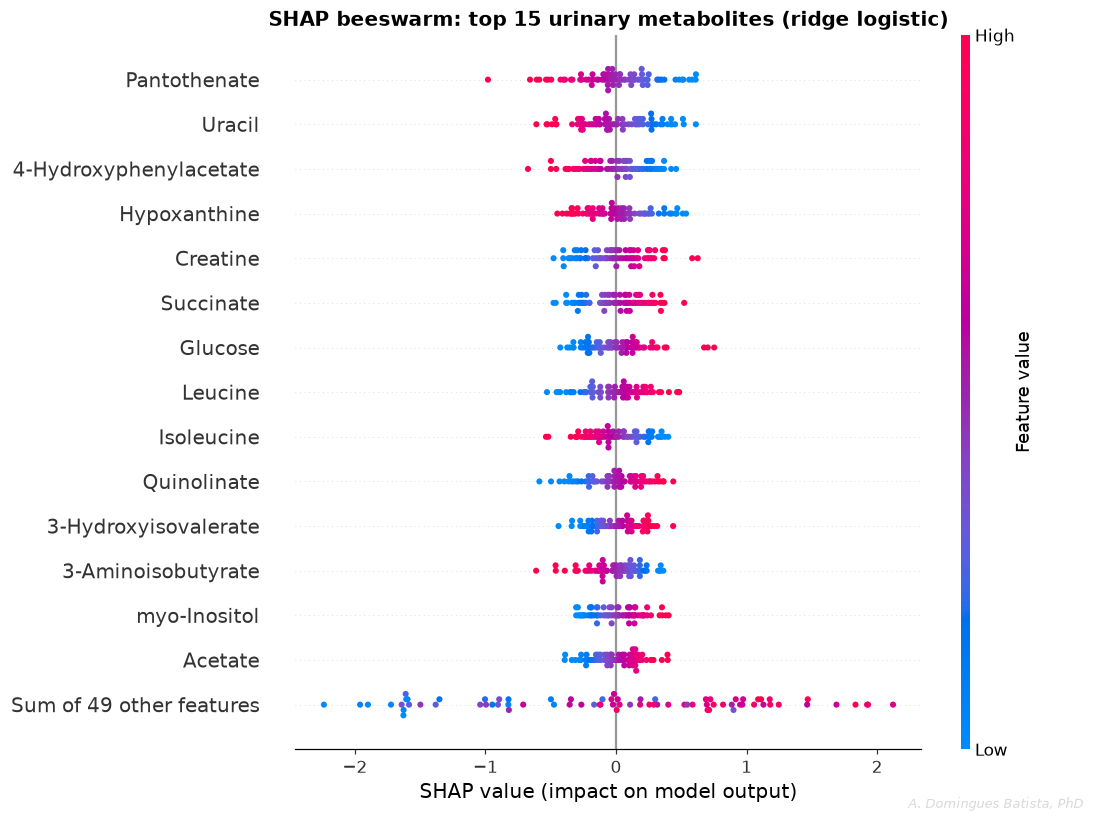

In [2]:
shap.plots.beeswarm(shap_vals, max_display=15, show=False)
fig = plt.gcf(); fig.set_size_inches(10, 7.5)
plt.title("SHAP beeswarm: top 15 urinary metabolites (ridge logistic)", fontsize=13, weight="bold")
fig.text(0.99, 0.01, 'A. Domingues Batista, PhD', ha='right', va='bottom', fontsize=8.5, color='gray', alpha=0.3, style='italic')
plt.tight_layout(); plt.savefig(FIG_DIR / "shap_beeswarm.png", bbox_inches="tight"); plt.show()


Each dot is one patient; red = high concentration. For metabolites with **positive** weights (e.g., creatine, succinate, glucose), high levels push towards cachexia. Several top features have **negative** weights even though their raw levels are *higher* in cachexia (e.g., pantothenate, uracil). Because all metabolites rise together with urine concentration, the model learns contrasts: a patient whose uracil is *low relative to everything else* looks cachexic. This matches the PQN analysis, where uracil is significantly lower after dilution correction.

## 2. Biomarker ranking: combining the three lines of evidence

In [3]:
uni = pd.read_csv("univariate_results.csv").set_index("Metabolite")
stab = pd.read_csv("lasso_stability.csv", index_col=0)["lasso_selection_freq"]

mean_abs = np.abs(shap_vals.values).mean(axis=0)
rank = pd.DataFrame({
    "mean_abs_SHAP": mean_abs,
    "model_weight": np.where(model.coef_.ravel() > 0, "+", "-"),
}, index=X.columns).join(uni[["log2FC", "q_value", "log2FC_pqn", "q_value_pqn"]]).join(stab)
rank = rank.sort_values("mean_abs_SHAP", ascending=False)
rank.insert(0, "Rank", range(1, len(rank) + 1))
# Shortlist: important to the model (top 15 SHAP) AND either stable in the Lasso or significant after dilution correction
rank["shortlist"] = (rank.Rank <= 15) & ((rank.lasso_selection_freq >= 0.5) | (rank.q_value_pqn < 0.05))
rank.round(3).to_csv("biomarker_ranking.csv")

top10_share = rank.mean_abs_SHAP.head(10).sum() / rank.mean_abs_SHAP.sum()
print(f"Top 10 metabolites carry {top10_share:.0%} of total mean |SHAP|")
print(f"Shortlist: {rank.shortlist.sum()} metabolites -> {rank.index[rank.shortlist].tolist()}")
rank.head(15).round(3)


Top 10 metabolites carry 34% of total mean |SHAP|
Shortlist: 9 metabolites -> ['Uracil', 'Creatine', 'Glucose', 'Leucine', 'Isoleucine', 'Quinolinate', '3-Hydroxyisovalerate', 'myo-Inositol', 'Acetate']


,Rank,mean_abs_SHAP,model_weight,log2FC,q_value,log2FC_pqn,q_value_pqn,lasso_selection_freq,shortlist
Pantothenate,1,0.241,-,0.460,0.251,-0.562,0.205,0.34,False
Uracil,2,0.228,-,0.329,0.313,-0.693,0.031,0.36,True
4-Hydroxyphenylacetate,3,0.198,-,0.610,0.046,-0.412,0.190,0.20,False
Hypoxanthine,4,0.197,-,0.598,0.117,-0.425,0.205,0.18,False
Creatine,5,0.192,+,1.796,0.000,0.774,0.190,0.70,True
Succinate,6,0.187,+,1.781,0.000,0.759,0.149,0.42,False
Glucose,7,0.186,+,1.618,0.000,0.596,0.136,0.78,True
Leucine,8,0.183,+,1.149,0.000,0.127,0.729,0.52,True
Isoleucine,9,0.180,-,0.470,0.064,-0.553,0.031,0.16,True
Quinolinate,10,0.175,+,1.238,0.000,0.216,0.487,0.88,True


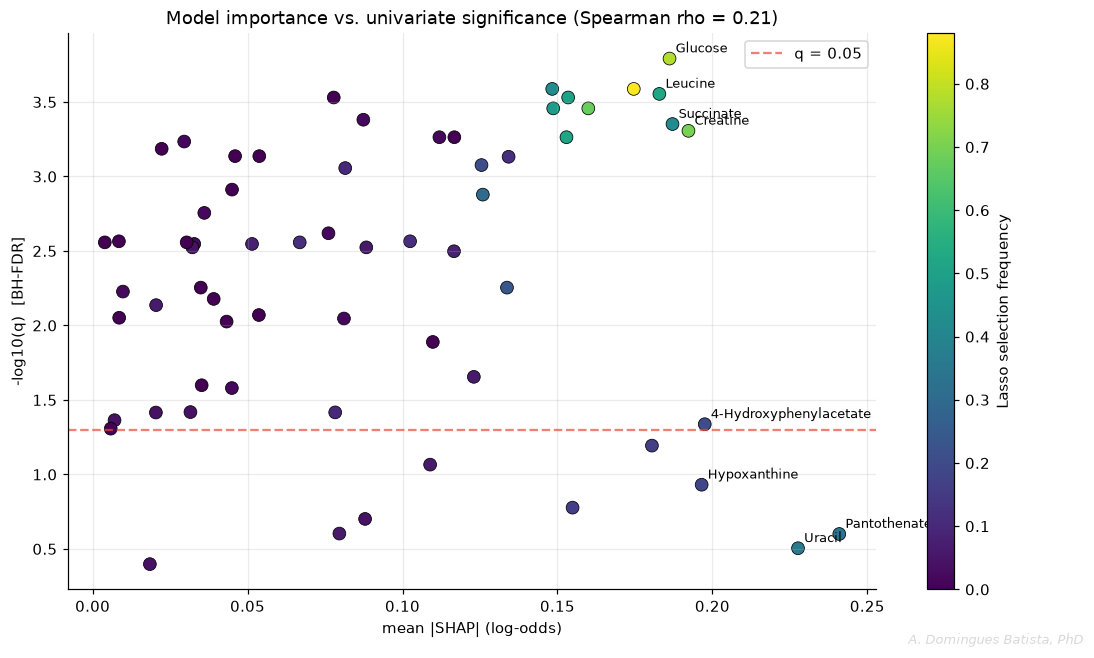

In [4]:
from scipy.stats import spearmanr
rho, p = spearmanr(rank.mean_abs_SHAP, -np.log10(rank.q_value))
fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(rank.mean_abs_SHAP, -np.log10(rank.q_value), c=rank.lasso_selection_freq,
                cmap="viridis", s=70, edgecolor="k", lw=0.5)
for name, r in rank.head(8).iterrows():
    ax.annotate(name, (r.mean_abs_SHAP, -np.log10(r.q_value)), fontsize=8.5, xytext=(4, 4), textcoords="offset points")
ax.axhline(-np.log10(0.05), ls="--", c="#E74C3C", alpha=0.7, label="q = 0.05")
ax.set(xlabel="mean |SHAP| (log-odds)", ylabel="-log10(q)  [BH-FDR]",
       title=f"Model importance vs. univariate significance (Spearman rho = {rho:.2f})")
plt.colorbar(sc, ax=ax, label="Lasso selection frequency")
ax.legend(); ax.grid(alpha=0.25)
fig.text(0.99, 0.01, 'A. Domingues Batista, PhD', ha='right', va='bottom', fontsize=8.5, color='gray', alpha=0.3, style='italic')
plt.tight_layout(); plt.savefig(FIG_DIR / "shap_vs_fdr.png", bbox_inches="tight"); plt.show()


## 3. Explaining a single patient

Patient PIF_087: P(cachexic) = 0.96


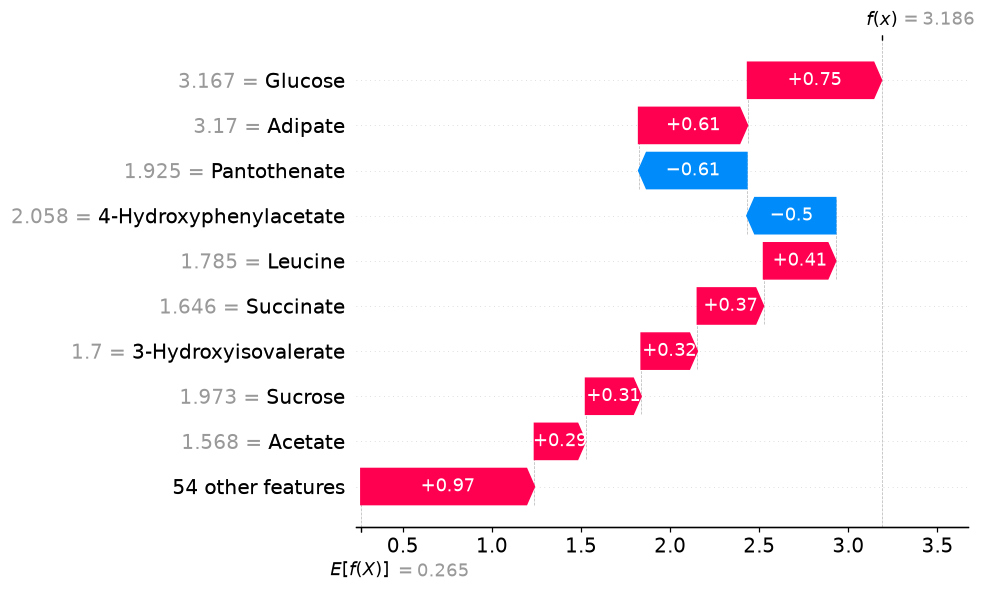

In [5]:
# The cachexic patient the model is most confident about
idx = int(np.argmax(model.predict_proba(X_std)[:, 1] * y))
print(f"Patient {df.Sample[idx]}: P(cachexic) = {model.predict_proba(X_std)[idx, 1]:.2f}")
shap.plots.waterfall(shap_vals[idx], max_display=10, show=False)
plt.gcf().set_size_inches(9, 5.5); plt.tight_layout(); plt.show()


## Takeaways

- **SHAP ≠ univariate.** Model importance and raw significance agree only weakly (Spearman ρ ≈ 0.2). The model relies on *relative* patterns (some metabolites high, others low compared with overall concentration), which a one-metabolite-at-a-time t-test cannot see. The two metabolites that survive dilution correction (**uracil** and **isoleucine**) are both in the model's top 10.
- **Shortlist.** The candidate panel combines SHAP importance with Lasso stability or post-PQN significance (see `biomarker_ranking.csv`).
- **Caveats.** n = 77 from a single study. Global urine concentration is the dominant signal, and it may be biology or pre-analytical. Correlated metabolites share credit in SHAP, and the Lasso's choice among them is unstable. Treat this ranking as prioritisation for validation, not as proof of diagnostic value.

**Next experimental steps**
1. Standardise urine collection (first-morning or 24 h) and record specific gravity/osmolality, so dilution can be separated from biology
2. Targeted, absolutely-quantified assay (e.g., LC-MS/MS MRM or targeted NMR) for the shortlist
3. Validation in an independent cohort, with a pre-registered decision threshold
4. Pathway mapping (HMDB/KEGG) to connect the panel to muscle protein catabolism
